# **Fase 1: Componente de IA Clásica (Minimax Alfa-Beta) y Generación de Datos**
## **Tres en Raya (3×3), paso a paso**

Construiremos el motor de reglas de Tres en Raya, implementaremos el algoritmo de búsqueda adversaria **Minimax con poda Alfa-Beta** y recorreremos el árbol completo de estados válidos para generar nuestro conjunto de datos (`dataset_tres_en_raya.csv`).

**Nivel:** introductorio-intermedio. **Objetivo:** obtener un oráculo determinista exacto y exportar los 2.423 estados legales de decisión de la IA sin valores nulos ni duplicados.

## **1. Preparar las herramientas**

Usaremos `NumPy` y `pandas` para estructurar los estados del tablero, `Matplotlib` para visualizar la distribución de las jugadas óptimas y `time` para auditar la latencia en milisegundos del algoritmo Minimax con poda Alfa-Beta.

In [1]:
import time
import random
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEMILLA = 42
random.seed(SEMILLA)
np.random.seed(SEMILLA)

RUTA_CSV = Path("../data/dataset_tres_en_raya.csv")

plt.rcParams.update({
    "figure.figsize": (7.5, 4.0),
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
})
print("Herramientas listas. Semilla fijada en:", SEMILLA)

Herramientas listas. Semilla fijada en: 42


## **2. Modelado formal del tablero y Minimax con poda Alfa-Beta**

Representamos el tablero 3×3 como un vector unidimensional de 9 enteros:
* `-1`: ficha del **Humano (X)**
* `0`: casilla **vacía**
* `1`: ficha de la **IA (O)**

La función de utilidad asigna `+10 - profundidad` si gana la IA (priorizando victorias rápidas), `profundidad - 10` si gana el humano y `0` en caso de empate.

In [2]:
LINEAS_GANADORAS = [
    (0, 1, 2), (3, 4, 5), (6, 7, 8),  # Filas
    (0, 3, 6), (1, 4, 7), (2, 5, 8),  # Columnas
    (0, 4, 8), (2, 4, 6)              # Diagonales
]

def verificar_ganador(tablero):
    for a, b, c in LINEAS_GANADORAS:
        if tablero[a] != 0 and tablero[a] == tablero[b] == tablero[c]:
            return tablero[a]
    if 0 not in tablero:
        return 0
    return None

def minimax_alfa_beta(tablero, profundidad, es_maximizador, alfa=-999, beta=999, contador=None):
    if contador is not None:
        contador["nodos"] += 1
    ganador = verificar_ganador(tablero)
    if ganador == 1:
        return 10 - profundidad
    if ganador == -1:
        return profundidad - 10
    if ganador == 0:
        return 0

    if es_maximizador:
        mejor = -999
        for i in range(9):
            if tablero[i] == 0:
                tablero[i] = 1
                puntaje = minimax_alfa_beta(tablero, profundidad + 1, False, alfa, beta, contador)
                tablero[i] = 0
                mejor = max(mejor, puntaje)
                alfa = max(alfa, mejor)
                if beta <= alfa:
                    break
        return mejor
    else:
        mejor = 999
        for i in range(9):
            if tablero[i] == 0:
                tablero[i] = -1
                puntaje = minimax_alfa_beta(tablero, profundidad + 1, True, alfa, beta, contador)
                tablero[i] = 0
                mejor = min(mejor, puntaje)
                beta = min(beta, mejor)
                if beta <= alfa:
                    break
        return mejor

def mejor_jugada_minimax(tablero):
    disponibles = [i for i in range(9) if tablero[i] == 0]
    evaluaciones = []
    nodos_totales = 0
    for i in disponibles:
        contador = {"nodos": 0}
        tablero[i] = 1
        puntaje = minimax_alfa_beta(tablero, 0, False, contador=contador)
        tablero[i] = 0
        nodos_totales += contador["nodos"]
        evaluaciones.append({"casilla": i, "puntaje_minimax": puntaje, "nodos_evaluados": contador["nodos"]})
    df_eval = pd.DataFrame(evaluaciones).sort_values(by=["puntaje_minimax", "casilla"], ascending=[False, True])
    return int(df_eval.iloc[0]["casilla"]), df_eval, nodos_totales

# Pruebas unitarias funcionales (CP-01 a CP-04)
casos_prueba = [
    ("CP-01 (Bloqueo amenaza en casilla 2)", [-1, -1, 0, 0, 1, 0, 0, 0, 0], 2),
    ("CP-02 (Victoria directa en casilla 2)", [1, 1, 0, -1, -1, 0, 0, 0, 0], 2),
    ("CP-03 (Control centro ante esquina)", [-1, 0, 0, 0, 0, 0, 0, 0, 0], 4),
    ("CP-04 (Bifurcación / doble amenaza)", [1, 0, 0, 0, -1, 0, 0, 0, 1], 2),
]

resultados_cp = []
for nombre_cp, estado_b, esperado in casos_prueba:
    t0 = time.perf_counter()
    elegida, _, nodos = mejor_jugada_minimax(list(estado_b))
    lat_ms = round((time.perf_counter() - t0) * 1000, 2)
    assert elegida == esperado, f"Error en {nombre_cp}: esperado {esperado}, obtenido {elegida}"
    resultados_cp.append({"Caso": nombre_cp, "Esperado": esperado, "Obtenido": elegida, "Nodos": nodos, "Tiempo (ms)": lat_ms, "Estado": "Aprobado"})

display(pd.DataFrame(resultados_cp))

,Caso,Esperado,Obtenido,Nodos,Tiempo (ms),Estado
0,CP-01 (Bloqueo amenaza en casilla 2),2,2,220,2.28,Aprobado
1,CP-02 (Victoria directa en casilla 2),2,2,64,0.51,Aprobado
2,CP-03 (Control centro ante esquina),4,4,6304,8.36,Aprobado
3,CP-04 (Bifurcación / doble amenaza),2,2,465,0.95,Aprobado


## **3. Generación exhaustiva del conjunto de datos (2.423 estados legales)**

Exploramos recursivamente todas las partidas legales posibles desde ambos turnos iniciales para registrar cada configuración no terminal donde debe actuar la IA junto con su etiqueta `jugada_optima`.

In [3]:
estados = {}

def explorar_arbol(tablero, turno):
    clave = tuple(tablero)
    if clave in estados or verificar_ganador(tablero) is not None:
        return
    if turno == 1:
        jugada, _, _ = mejor_jugada_minimax(tablero)
        estados[clave] = jugada
    for i in range(9):
        if tablero[i] == 0:
            tablero[i] = turno
            explorar_arbol(tablero, -turno)
            tablero[i] = 0

explorar_arbol([0]*9, 1)
explorar_arbol([0]*9, -1)

columnas = [f"celda_{i}" for i in range(9)] + ["jugada_optima"]
datos = pd.DataFrame([list(k) + [v] for k, v in estados.items()], columns=columnas)

# Auditoría de calidad de datos
assert len(datos) == 2423, f"Total inesperado: {len(datos)}"
assert not datos.isna().any().any(), "Se detectaron nulos"
assert datos.duplicated().sum() == 0, "Se detectaron duplicados"

datos.to_csv(RUTA_CSV, index=False, encoding="utf-8")
print(f"Dataset exportado con éxito: {len(datos)} estados únicos, 0 nulos, 0 duplicados.")
display(datos.head(8))

Dataset exportado con éxito: 2423 estados únicos, 0 nulos, 0 duplicados.


,celda_0,celda_1,celda_2,celda_3,celda_4,celda_5,celda_6,celda_7,celda_8,jugada_optima
0,0,0,0,0,0,0,0,0,0,0
1,1,-1,0,0,0,0,0,0,0,3
2,1,-1,1,-1,0,0,0,0,0,4
3,1,-1,1,-1,1,-1,0,0,0,6
4,1,-1,1,-1,1,-1,-1,1,0,8
5,1,-1,1,-1,1,-1,0,1,-1,6
6,1,-1,1,-1,1,0,-1,0,0,8
7,1,-1,1,-1,1,1,-1,-1,0,8


## **4. Análisis exploratorio de la variable objetivo (`jugada_optima`)**

Verificamos la distribución de frecuencias de cada casilla óptima en los 2.423 estados legales.

,casilla,frecuencia,porcentaje_%
0,0,458,18.90
1,1,245,10.11
2,2,356,14.69
3,3,199,8.21
4,4,401,16.55
5,5,162,6.69
6,6,246,10.15
7,7,132,5.45
8,8,224,9.24


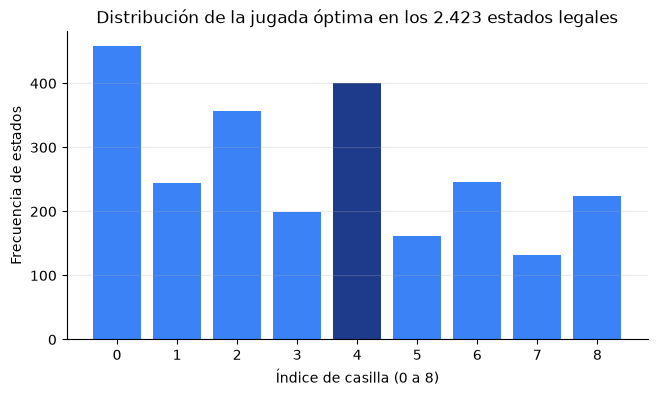

In [4]:
conteo = datos["jugada_optima"].value_counts().sort_index()
porc = (conteo / len(datos) * 100).round(2)
resumen_clases = pd.DataFrame({"casilla": conteo.index, "frecuencia": conteo.values, "porcentaje_%": porc.values})
display(resumen_clases)

fig, ax = plt.subplots()
colores = ["#1E3A8A" if c == 4 else "#3B82F6" for c in resumen_clases["casilla"]]
ax.bar(resumen_clases["casilla"].astype(str), resumen_clases["frecuencia"], color=colores)
ax.set(title="Distribución de la jugada óptima en los 2.423 estados legales",
       xlabel="Índice de casilla (0 a 8)", ylabel="Frecuencia de estados")
ax.grid(axis="y", alpha=0.25)
fig.savefig("../evidencias/fig_distribucion_clases.png", bbox_inches="tight", dpi=150)
plt.show()